# BERT-Based Movie Review Sentiment Analysis
**An NLP project using IMDb reviews and a pretrained BERT model**

## Project goal
Fine-tune `bert-base-uncased` to classify movie reviews as **positive (1)** or **negative (0)**.

### What this project demonstrates
- Text classification with a pretrained Transformer
- BERT tokenization and attention masks
- Fine-tuning a pretrained model
- A proper train / validation / test split (the test set is used only once, for the final report)
- Evaluation using accuracy, precision, recall, F1-score and a confusion matrix
- Predictions on reviews written by hand
- Saving and reloading the trained model

**Runtime:** Google Colab, preferably GPU enabled.  
**Framework:** Hugging Face Transformers with PyTorch.

## 1. Install dependencies
Run this cell once. If Colab asks you to restart the runtime, do so and then continue from the imports cell.

In [1]:
%pip install -q -U transformers datasets accelerate scikit-learn matplotlib pandas

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


## 2. Import libraries and check hardware

In [2]:
import os, random, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from datasets import load_dataset, Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


## 3. Load the IMDb dataset

This uses the IMDb dataset from Hugging Face. The first run needs internet access to download the dataset and model.

For a faster first experiment, this notebook selects a manageable subset. Increase the limits later if you have enough GPU time.

In [4]:
# Increase these (up to 25000 each) for a stronger final run.
TRAIN_LIMIT = 8000
TEST_LIMIT = 2000

raw = load_dataset("stanfordnlp/imdb")
train_df = raw["train"].shuffle(seed=SEED).select(
    range(min(TRAIN_LIMIT, len(raw["train"])))
).to_pandas()
test_df = raw["test"].shuffle(seed=SEED).select(
    range(min(TEST_LIMIT, len(raw["test"])))
).to_pandas()

print("Training subset:", train_df.shape)
print("Test subset:", test_df.shape)
train_df.head()

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Training subset: (8000, 2)
Test subset: (2000, 2)


,text,label
0,There is no relation at all between Fortier an...,1
1,This movie is a great. The plot is very true t...,1
2,"George P. Cosmatos' ""Rambo: First Blood Part I...",0
3,In the process of trying to establish the audi...,1
4,"Yeh, I know -- you're quivering with excitemen...",0


### Optional alternative: use the Kaggle CSV

If the Hugging Face dataset download fails but you already downloaded `IMDB Dataset.csv` from Kaggle, run this cell instead of Section 3. It expects columns named `review` and `sentiment`.

In [5]:
# OPTIONAL: run only if you want to use the Kaggle CSV instead of Section 3.
# from google.colab import files
# uploaded = files.upload()  # choose "IMDB Dataset.csv"
# csv_name = next(iter(uploaded))
# all_df = pd.read_csv(csv_name)
# all_df = all_df.rename(columns={"review": "text", "sentiment": "label"})
# all_df["label"] = all_df["label"].map({"negative": 0, "positive": 1})
# all_df = all_df.dropna(subset=["text", "label"])
# all_df["label"] = all_df["label"].astype(int)
# train_df, test_df = train_test_split(
#     all_df, test_size=0.2, random_state=SEED, stratify=all_df["label"]
# )
# train_df = train_df.reset_index(drop=True)
# test_df = test_df.reset_index(drop=True)

## 4. Inspect the data

Note: IMDb reviews contain HTML line-break tags (`<br />`). They are left in place; BERT's tokenizer splits them into a few harmless tokens.

['text', 'label']
                                                text  label
0  There is no relation at all between Fortier an...      1
1  This movie is a great. The plot is very true t...      1
2  George P. Cosmatos' "Rambo: First Blood Part I...      0

Label counts in training subset:
label
0    3988
1    4012
Name: count, dtype: int64


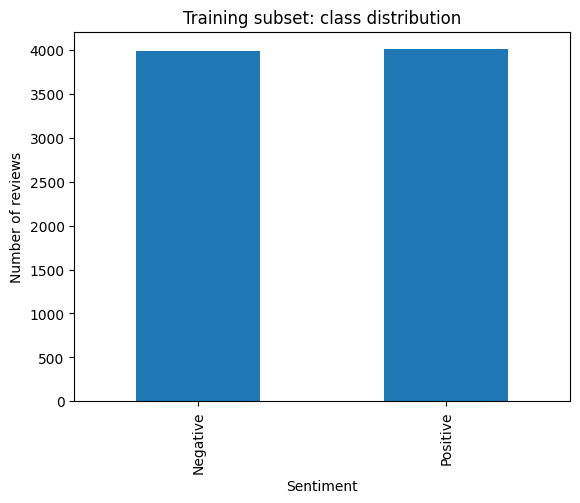

In [6]:
print(train_df.columns.tolist())
print(train_df[["text", "label"]].head(3))
print("\nLabel counts in training subset:")
print(train_df["label"].value_counts().sort_index())

label_names = {0: "Negative", 1: "Positive"}
train_df["label"].value_counts().sort_index().rename(index=label_names).plot(kind="bar")
plt.title("Training subset: class distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.show()

## 5. Create a validation split

The validation set is used during training to pick the best epoch. The test set stays untouched until the final evaluation, so the reported test metrics are not biased by model selection.

In [7]:
train_part, val_part = train_test_split(
    train_df, test_size=0.1, random_state=SEED, stratify=train_df["label"]
)
train_part = train_part.reset_index(drop=True)
val_part = val_part.reset_index(drop=True)

print("Train:", len(train_part), "| Validation:", len(val_part), "| Test:", len(test_df))

Train: 7200 | Validation: 800 | Test: 2000


## 6. Tokenize text with BERT

BERT does not receive raw strings directly. Its tokenizer converts text into token IDs and creates attention masks. We do **not** remove stopwords or punctuation as in some traditional NLP pipelines; they may carry useful meaning and BERT was pretrained with its own tokenizer.

`MAX_LENGTH = 256` truncates long reviews. Raising it to 512 usually improves accuracy slightly but needs more memory and time.

In [8]:
MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 256

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_batch(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

def to_tokenized_dataset(df):
    ds = Dataset.from_pandas(df[["text", "label"]].reset_index(drop=True))
    ds = ds.map(tokenize_batch, batched=True)
    ds = ds.remove_columns(["text"])
    ds = ds.rename_column("label", "labels")
    return ds

train_ds = to_tokenized_dataset(train_part)
val_ds = to_tokenized_dataset(val_part)
test_ds = to_tokenized_dataset(test_df)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
print(train_ds[0].keys())

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/7200 [00:00<?, ? examples/s]

Map:   0%|          | 0/800 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

dict_keys(['labels', 'input_ids', 'token_type_ids', 'attention_mask'])


## 7. Load the pretrained BERT classifier

The pretrained BERT encoder provides contextual representations. A classification head is added for the two sentiment labels. Fine-tuning updates the model parameters using IMDb examples.

In [9]:
id2label = {0: "NEGATIVE", 1: "POSITIVE"}
label2id = {"NEGATIVE": 0, "POSITIVE": 1}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=id2label,
    label2id=label2id
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## 8. Define evaluation metrics and train

Starter settings: 2 epochs, batch size 8. GPU training is recommended. The best epoch is chosen by F1 on the **validation** set.

Note: newer Transformers versions use `processing_class` instead of the deprecated `tokenizer` argument of `Trainer`.

In [11]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average="binary", zero_division=0
    )
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

training_args = TrainingArguments(
    output_dir="./bert-imdb-checkpoints",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=100,
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=2,
    report_to="none",
    fp16=torch.cuda.is_available(),
    seed=SEED
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

train_result = trainer.train()
print(train_result)

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.120088,0.434765,0.912500,0.918987,0.905237,0.912060
2,0.112724,0.449239,0.915000,0.909091,0.922693,0.915842


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=1800, training_loss=0.10472090601921082, metrics={'train_runtime': 266.3987, 'train_samples_per_second': 54.054, 'train_steps_per_second': 6.757, 'total_flos': 1892882598913440.0, 'train_loss': 0.10472090601921082, 'epoch': 2.0})


## 9. Evaluate the model

Validation metrics come from the best epoch; test metrics are the final, unbiased result to report.

In [12]:
val_metrics = trainer.evaluate(val_ds, metric_key_prefix="val")
print("Validation metrics:")
for key, value in val_metrics.items():
    if isinstance(value, (int, float)):
        print(f"  {key}: {value:.4f}")

test_metrics = trainer.evaluate(test_ds, metric_key_prefix="test")
print("\nTest metrics (report these):")
for key, value in test_metrics.items():
    if isinstance(value, (int, float)):
        print(f"  {key}: {value:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.112724,0.449239,2,0.915000,0.909091,0.922693,0.915842


Validation metrics:
  val_loss: 0.4492
  val_accuracy: 0.9150
  val_precision: 0.9091
  val_recall: 0.9227
  val_f1: 0.9158


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.112724,0.491736,2,0.905000,0.906627,0.903000,0.904810



Test metrics (report these):
  test_loss: 0.4917
  test_accuracy: 0.9050
  test_precision: 0.9066
  test_recall: 0.9030
  test_f1: 0.9048


## 10. Classification report and confusion matrix (test set)

              precision    recall  f1-score   support

    Negative     0.9034    0.9070    0.9052      1000
    Positive     0.9066    0.9030    0.9048      1000

    accuracy                         0.9050      2000
   macro avg     0.9050    0.9050    0.9050      2000
weighted avg     0.9050    0.9050    0.9050      2000



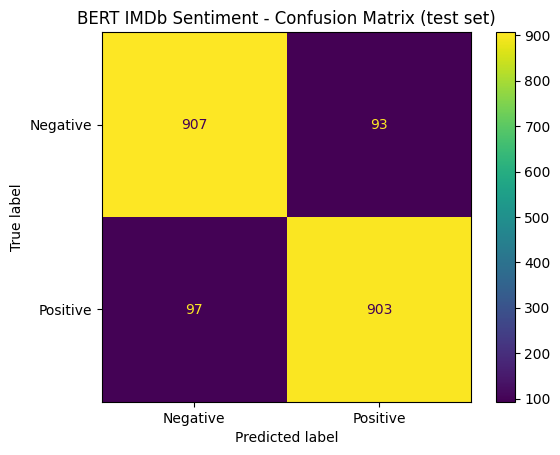

In [13]:
pred_output = trainer.predict(test_ds)
y_true = pred_output.label_ids
y_pred = np.argmax(pred_output.predictions, axis=1)

print(classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)
display.plot(values_format="d")
plt.title("BERT IMDb Sentiment - Confusion Matrix (test set)")
plt.show()

## 11. Try custom reviews

In [14]:
def predict_sentiment(review):
    model.eval()
    inputs = tokenizer(
        review,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH
    )
    inputs = {k: v.to(model.device) for k, v in inputs.items()}
    with torch.no_grad():
        logits = model(**inputs).logits
        probs = torch.softmax(logits, dim=-1)[0]
    pred_id = int(torch.argmax(probs).item())
    return {
        "review": review,
        "prediction": id2label[pred_id],
        "negative_probability": round(float(probs[0]), 4),
        "positive_probability": round(float(probs[1]), 4)
    }

examples = [
    "The acting was excellent and the story kept me interested until the end.",
    "The plot was boring, the dialogue was weak, and I regret watching it.",
    "It was not bad, although I expected something more memorable."
]
for review in examples:
    print(predict_sentiment(review), "\n")

{'review': 'The acting was excellent and the story kept me interested until the end.', 'prediction': 'POSITIVE', 'negative_probability': 0.0013, 'positive_probability': 0.9987} 

{'review': 'The plot was boring, the dialogue was weak, and I regret watching it.', 'prediction': 'NEGATIVE', 'negative_probability': 0.998, 'positive_probability': 0.002} 

{'review': 'It was not bad, although I expected something more memorable.', 'prediction': 'POSITIVE', 'negative_probability': 0.0015, 'positive_probability': 0.9985} 



## 12. Save and reload the model

In [15]:
SAVE_DIR = "./bert-imdb-sentiment-model"
trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
print("Saved model and tokenizer to:", SAVE_DIR)

# Verify that the saved model can be loaded again.
reloaded_tokenizer = AutoTokenizer.from_pretrained(SAVE_DIR)
reloaded_model = AutoModelForSequenceClassification.from_pretrained(SAVE_DIR)
reloaded_model.to(DEVICE)
reloaded_model.eval()

def predict_with_reloaded_model(review):
    batch = reloaded_tokenizer(
        review, return_tensors="pt", truncation=True, max_length=MAX_LENGTH
    ).to(DEVICE)
    with torch.no_grad():
        probs = torch.softmax(reloaded_model(**batch).logits, dim=-1)[0]
    label_id = int(torch.argmax(probs).item())
    return id2label[label_id], float(probs[label_id])

predict_with_reloaded_model("A wonderful film with believable characters.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model and tokenizer to: ./bert-imdb-sentiment-model


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

('POSITIVE', 0.99888676404953)

## 13. Download the trained model (optional)

The model folder is saved in the current Colab runtime. To keep it after the runtime ends, download it or save it to Google Drive. The following cell zips the folder for download.

In [16]:
import shutil
zip_path = shutil.make_archive("bert-imdb-sentiment-model", "zip", SAVE_DIR)
print("Created:", zip_path)

# In Google Colab, uncomment these lines to download the zip:
# from google.colab import files
# files.download(zip_path)

Created: /content/bert-imdb-sentiment-model.zip


## 14. Interview explanation

**30-second project summary**

"I built a binary sentiment-classification system using a pretrained BERT model and the IMDb movie-review dataset. I tokenized each review with BERT's tokenizer, fine-tuned `bert-base-uncased` with a two-class classification head, and selected the best epoch on a held-out validation set. I then reported accuracy, precision, recall, F1-score and a confusion matrix on a separate test set. I also implemented custom-review inference and saved/reloaded the trained model."

### Questions you should be ready to answer
1. Why use BERT instead of a basic embedding + dense model?
2. What are contextual embeddings?
3. What do `[CLS]`, `[SEP]`, token IDs and attention masks do?
4. What is self-attention, at a high level?
5. What is fine-tuning, and how is it different from training from scratch?
6. Why use a small learning rate such as `2e-5`?
7. Why do we use truncation and a maximum sequence length?
8. Explain precision, recall, F1-score and the confusion matrix.
9. Why a separate validation set in addition to the test set?
10. What are limitations of this project? (binary labels, dataset domain, maximum input length, possible overfitting, and runtime constraints)
11. How would you deploy it? (e.g. a small Streamlit interface or API, after validating the model and packaging dependencies)

### Important
- Report the **actual metrics from your run**; do not invent a result before training.
- This notebook uses a subset by default (8,000 training reviews, of which 10% become validation, and 2,000 test reviews). Mention the subset sizes accurately in your project documentation.
- The first download requires internet access. If the Hugging Face dataset download is blocked in your environment, use the optional Kaggle CSV cell.